# Quasi-Monte Carlo con secuencias de Sobol

**Simulación de Procesos Financieros, ITESO**

Monte Carlo usa números aleatorios, que se amontonan en unas zonas y dejan huecos en otras. Por eso su error baja lento, como $1/\sqrt{N}$.

**Quasi-Monte Carlo (QMC)** reemplaza esos números por **secuencias de baja discrepancia**: puntos deterministas diseñados para cubrir el espacio de forma pareja. La más usada es la de **Sobol**. El resto del método no cambia: se generan escenarios, se calcula el payoff, se promedia y se descuenta.

| | Monte Carlo | Quasi-Monte Carlo |
|---|---|---|
| Puntos | Pseudoaleatorios | Secuencia de Sobol |
| Cobertura | Con huecos y amontonamientos | Pareja |
| Error | $\sim 1/\sqrt{N}$ | cercano a $1/N$ |

**Contenido:**
1. Introducción: cómo se distribuyen los números pseudoaleatorios y cómo los de Sobol, y su efecto al estimar una integral.
2. Valuación de una call europea y una asiática con QMC, comparada contra Monte Carlo normal.

### Librerías

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm, qmc

---
## Parte 1. Introducción

### 1.1 Números pseudoaleatorios uniformes

Si los números fueran perfectamente uniformes en $[0, 1]$, el histograma sería plano: todas las barras de la misma altura.

### Histograma de 50 números uniformes

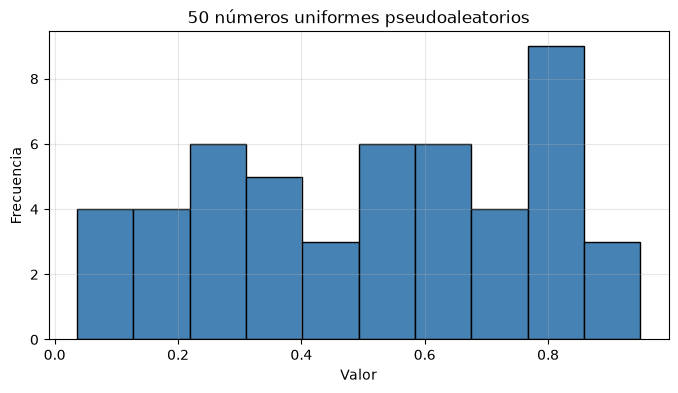

In [2]:
np.random.seed(20)
m = np.random.uniform(0, 1, 50)

plt.figure(figsize=(8, 4))
plt.hist(m, bins=10, color="steelblue", edgecolor="black")
plt.title("50 números uniformes pseudoaleatorios")
plt.xlabel("Valor"); plt.ylabel("Frecuencia")
plt.grid(alpha=0.3)
plt.show()

Con solo 50 números el histograma está lejos de ser plano: hay barras con 3 valores y otras con 9. Hay zonas sobrerrepresentadas y otras con huecos.

### Histogramas al aumentar el número de valores

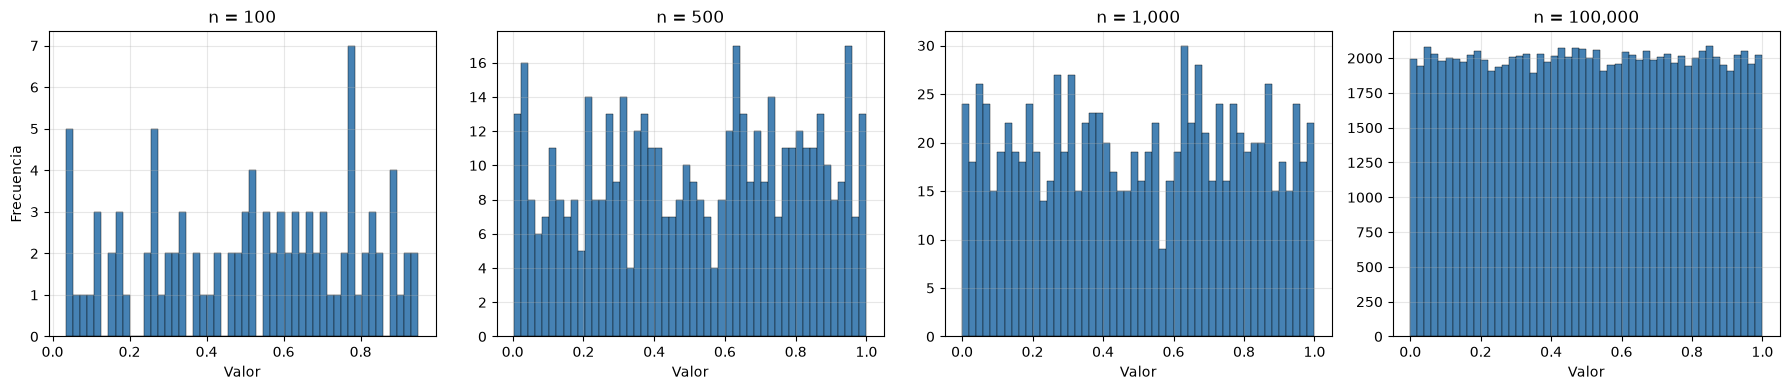

In [3]:
tamanos = [100, 500, 1000, 100000]
fig, axes = plt.subplots(1, 4, figsize=(18, 4))

for ax, n_val in zip(axes, tamanos):
    np.random.seed(20)
    m = np.random.uniform(0, 1, n_val)
    ax.hist(m, bins=50, color="steelblue", edgecolor="black", linewidth=0.3)
    ax.set_title(f"n = {n_val:,}")
    ax.set_xlabel("Valor")
    ax.grid(alpha=0.3)

axes[0].set_ylabel("Frecuencia")
plt.tight_layout()
plt.show()

Al aumentar $n$ el histograma se va pareciendo a la forma de una uniforme, cada vez más plano. Pero para lograrlo hacen falta muchísimos números: con 1,000 todavía se notan barras irregulares, y solo con 100,000 se ve realmente parejo. Esa es la lentitud de Monte Carlo.

### 1.2 Pseudoaleatorio vs Sobol

Ahora se compara con la misma cantidad de puntos generados con Sobol. Se usan potencias de 2 porque Sobol conserva sus propiedades de cobertura pareja solo con esos tamaños.

### Histogramas: pseudoaleatorio vs Sobol

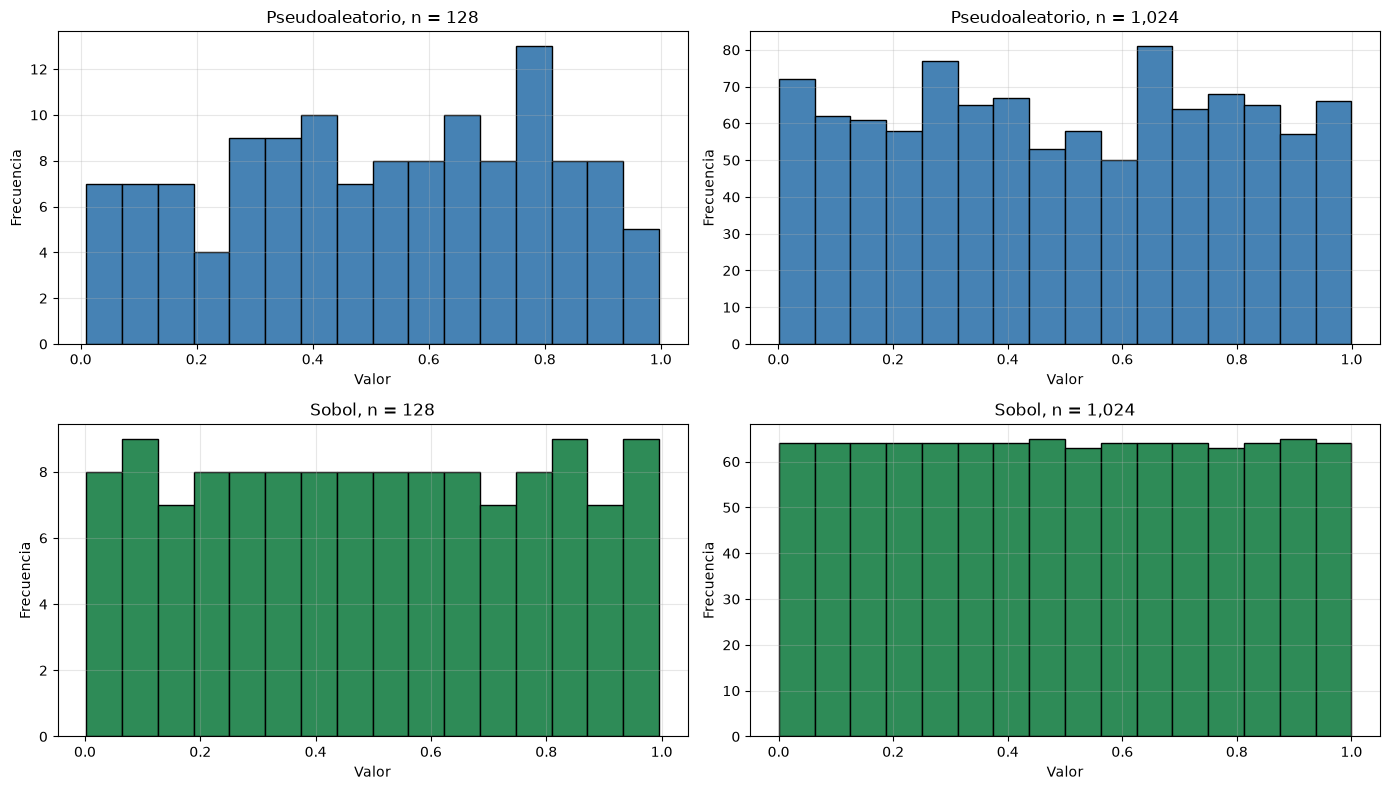

In [4]:
tamanos = [128, 1024]
fig, axes = plt.subplots(2, 2, figsize=(14, 8))

for j, n_val in enumerate(tamanos):
    np.random.seed(20)
    u_mc  = np.random.uniform(0, 1, n_val)
    u_sob = qmc.Sobol(d=1, scramble=True, seed=42).random(n_val).ravel()

    axes[0, j].hist(u_mc, bins=16, color="steelblue", edgecolor="black")
    axes[0, j].set_title(f"Pseudoaleatorio, n = {n_val:,}")
    axes[1, j].hist(u_sob, bins=16, color="seagreen", edgecolor="black")
    axes[1, j].set_title(f"Sobol, n = {n_val:,}")

for ax in axes.flat:
    ax.set_xlabel("Valor"); ax.set_ylabel("Frecuencia"); ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

Con Sobol el histograma es **prácticamente plano** desde 128 puntos: lo ideal son 8 valores por barra y cada barra tiene entre 7 y 9. Con 1,024 lo ideal son 64 y Sobol da entre 63 y 65, mientras que los pseudoaleatorios van de 50 a 81. Para acercarse a esa uniformidad con números aleatorios harían falta cientos de miles de puntos.

### Cobertura en dos dimensiones

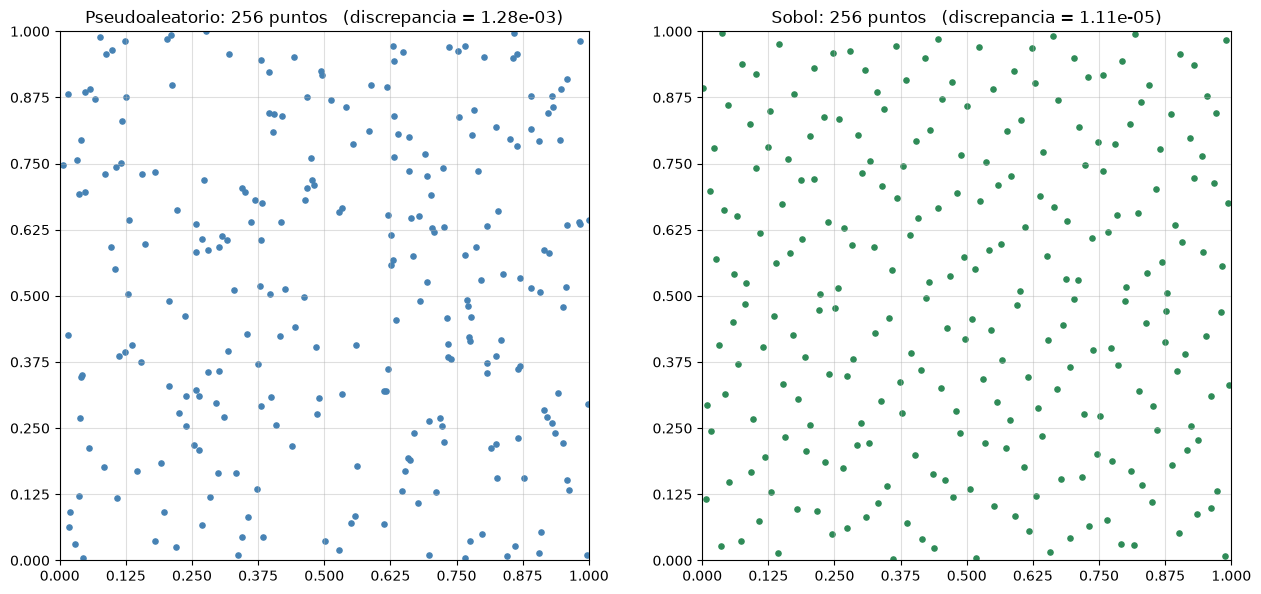

In [5]:
n_val = 256
np.random.seed(20)
p_mc  = np.random.uniform(0, 1, (n_val, 2))
p_sob = qmc.Sobol(d=2, scramble=True, seed=42).random(n_val)

fig, axes = plt.subplots(1, 2, figsize=(13, 6))
for ax, pts, nombre, color in [(axes[0], p_mc, "Pseudoaleatorio", "steelblue"),
                               (axes[1], p_sob, "Sobol", "seagreen")]:
    ax.scatter(pts[:, 0], pts[:, 1], s=14, color=color)
    ax.set_title(f"{nombre}: {n_val} puntos   (discrepancia = {qmc.discrepancy(pts):.2e})")
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_aspect("equal")
    ax.set_xticks(np.linspace(0, 1, 9)); ax.set_yticks(np.linspace(0, 1, 9))
    ax.grid(alpha=0.4)

plt.tight_layout()
plt.show()

En el panel pseudoaleatorio hay cuadros con varios puntos juntos y otros vacíos. Con Sobol cada cuadro de la cuadrícula tiene aproximadamente la misma cantidad de puntos. La **discrepancia** mide justamente ese desbalance: entre más baja, más pareja la cobertura.

### 1.3 Estimación de una integral: $\int_0^1 x^2\,dx$

El valor exacto es $1/3$. Monte Carlo lo estima como el promedio de $x^2$ evaluado en puntos uniformes:

$$\int_0^1 x^2\,dx \approx \frac{1}{M}\sum_{i=1}^{M} x_i^2$$

Valuar una opción es exactamente lo mismo: el precio es una integral (un valor esperado) que se aproxima con un promedio.

### Integral con Monte Carlo y con QMC

In [6]:
M_lista = [128, 512, 1024, 4096]
a, b = 0, 1
exacto = 1/3

np.random.seed(20)
filas = []
for M in M_lista:
    x_mc  = np.random.uniform(a, b, M)
    x_sob = qmc.Sobol(d=1, scramble=True, seed=42).random(M).ravel()

    integral_mc  = np.mean(x_mc**2)  * (b - a)
    integral_qmc = np.mean(x_sob**2) * (b - a)

    filas.append({"M": M,
                  "Integral MC": integral_mc,
                  "Integral QMC": integral_qmc,
                  "Error MC": abs(integral_mc - exacto),
                  "Error QMC": abs(integral_qmc - exacto)})

tabla_integral = pd.DataFrame(filas)
tabla_integral

,M,Integral MC,Integral QMC,Error MC,Error QMC
0,128,0.341188,0.333333,0.007854,4.620233e-10
1,512,0.348865,0.333333,0.015532,6.948539e-10
2,1024,0.322519,0.333333,0.010814,4.656612e-10
3,4096,0.340185,0.333333,0.006851,4.656612e-10


### Convergencia promedio de cada método

Una sola corrida puede tener suerte. Para ver la tendencia real se repite cada cálculo 20 veces y se promedia el error absoluto, para tamaños de $2^4$ a $2^{14}$.

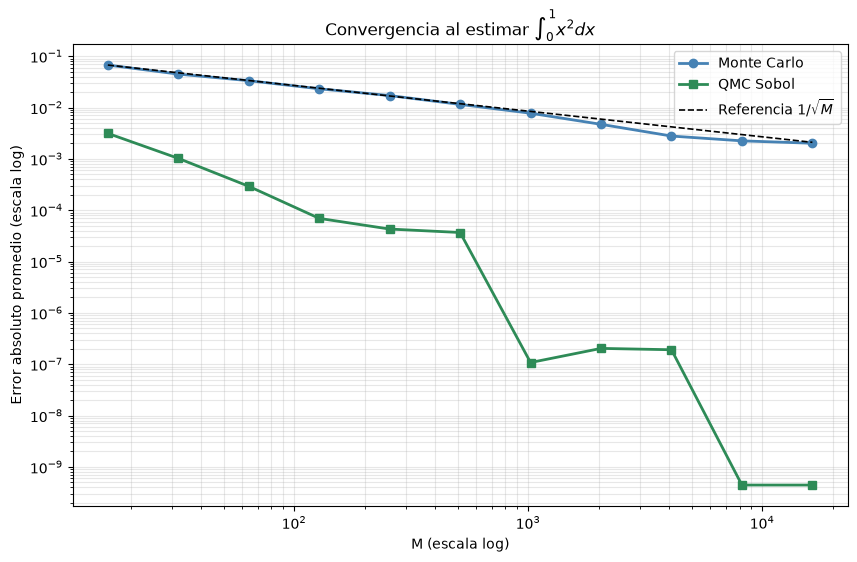

In [7]:
R = 20
tamanos = [2**k for k in range(4, 15)]
err_mc, err_qmc = [], []

for M in tamanos:
    e_mc, e_qmc = [], []
    for j in range(R):
        x_mc  = np.random.default_rng(j).uniform(0, 1, M)
        x_sob = qmc.Sobol(d=1, scramble=True, seed=j).random(M).ravel()
        e_mc.append(abs(np.mean(x_mc**2) - exacto))
        e_qmc.append(abs(np.mean(x_sob**2) - exacto))
    err_mc.append(np.mean(e_mc))
    err_qmc.append(np.mean(e_qmc))

plt.figure(figsize=(10, 6))
plt.loglog(tamanos, err_mc,  "o-", lw=2, color="steelblue", label="Monte Carlo")
plt.loglog(tamanos, err_qmc, "s-", lw=2, color="seagreen",  label="QMC Sobol")
plt.loglog(tamanos, err_mc[0]*np.sqrt(tamanos[0]/np.array(tamanos)), "k--", lw=1.2,
           label="Referencia $1/\\sqrt{M}$")
plt.xlabel("M (escala log)"); plt.ylabel("Error absoluto promedio (escala log)")
plt.title("Convergencia al estimar $\\int_0^1 x^2 dx$")
plt.legend(); plt.grid(alpha=0.3, which="both")
plt.show()

**Interpretación.** El error de Monte Carlo baja siguiendo la línea de referencia $1/\sqrt{M}$: con 16,384 puntos sigue en el orden de $10^{-3}$. El de Sobol baja muchísimo más rápido y llega al orden de $10^{-10}$, donde se estanca porque alcanza el límite de precisión numérica de la secuencia, no porque el método deje de mejorar.

En una dimensión y con una función suave como $x^2$, QMC es casi exacto. Hay que tener cuidado al extrapolar: con opciones el payoff tiene un "codo" en $K$ y las rutas necesitan muchas dimensiones, así que la mejora será real pero mucho menor, como se ve en la Parte 2.

---
## Parte 2. Valuación de opciones con QMC + Sobol

**Parámetros:** $S_0 = 100$, $K = 100$, $r = 5\%$, $\sigma = 20\%$, $T = 1$, con 252 pasos diarios y $M = 2^{10} = 1{,}024$ rutas.

Se valúan dos opciones:
- **Call europea:** usa el precio final $S_T$. Tiene fórmula de Black-Scholes para comparar.
- **Call asiática aritmética:** usa el promedio de los 252 precios diarios. No tiene fórmula cerrada.

Los puntos de Sobol viven en $[0, 1]$, así que se convierten a normales con la inversa de la distribución normal: $Z = \Phi^{-1}(U)$.

### Parámetros

In [8]:
S0, K, r, sigma, T = 100, 100, 0.05, 0.20, 1
n  = 252
dt = T / n
M  = 2**10
desc = np.exp(-r*T)

### Referencia: Black-Scholes para la call europea

In [9]:
d1 = (np.log(S0/K) + (r + 0.5*sigma**2)*T) / (sigma*np.sqrt(T))
d2 = d1 - sigma*np.sqrt(T)
bs = S0*norm.cdf(d1) - K*np.exp(-r*T)*norm.cdf(d2)

print(f"Black-Scholes = {bs:.6f}")

Black-Scholes = 10.450584


### Función para simular rutas a partir de una matriz Z

In [10]:
def simular_rutas(Z):
    S = np.zeros((Z.shape[0], n + 1))
    S[:, 0] = S0
    for i in range(n):
        S[:, i + 1] = S[:, i] * np.exp((r - 0.5*sigma**2)*dt + sigma*np.sqrt(dt)*Z[:, i])
    return S

### Puntos de Sobol convertidos a normales

Cada ruta necesita 252 números, uno por día, así que la dimensión es $d = 252$.

In [11]:
sobol = qmc.Sobol(d=n, scramble=True, seed=42)
U = sobol.random(M)
Z_qmc = norm.ppf(U)

print(f"Matriz U: {U.shape}   rango [{U.min():.4f}, {U.max():.4f}]")
print(f"Matriz Z: {Z_qmc.shape}   media {Z_qmc.mean():.4f}   desv. {Z_qmc.std():.4f}")

Matriz U: (1024, 252)   rango [0.0000, 1.0000]
Matriz Z: (1024, 252)   media -0.0000   desv. 1.0000


### Simulación de rutas con QMC

In [12]:
S_qmc = simular_rutas(Z_qmc)
print(f"Matriz de precios: {S_qmc.shape}")

Matriz de precios: (1024, 253)


### Payoffs y precios con QMC

In [13]:
payoff_eu_qmc   = np.maximum(S_qmc[:, -1] - K, 0)
payoff_asia_qmc = np.maximum(S_qmc[:, 1:].mean(axis=1) - K, 0)

precio_eu_qmc   = desc * payoff_eu_qmc.mean()
precio_asia_qmc = desc * payoff_asia_qmc.mean()

print(f"Call europea (QMC)  : {precio_eu_qmc:.4f}   Black-Scholes: {bs:.4f}")
print(f"Call asiática (QMC) : {precio_asia_qmc:.4f}")

Call europea (QMC)  : 10.4126   Black-Scholes: 10.4506
Call asiática (QMC) : 5.6995


### Comparación con Monte Carlo normal (mismo número de rutas)

In [14]:
np.random.seed(42)
Z_mc = np.random.normal(0, 1, (M, n))
S_mc = simular_rutas(Z_mc)

precio_eu_mc   = desc * np.maximum(S_mc[:, -1] - K, 0).mean()
precio_asia_mc = desc * np.maximum(S_mc[:, 1:].mean(axis=1) - K, 0).mean()

pd.DataFrame({
    "Opción": ["Call europea", "Call asiática"],
    "MC normal": [precio_eu_mc, precio_asia_mc],
    "QMC Sobol": [precio_eu_qmc, precio_asia_qmc],
    "Black-Scholes": [bs, np.nan]
}).round(4)

,Opción,MC normal,QMC Sobol,Black-Scholes
0,Call europea,10.3522,10.4126,10.4506
1,Call asiática,5.5951,5.6995,NaN


### Rutas simuladas con QMC

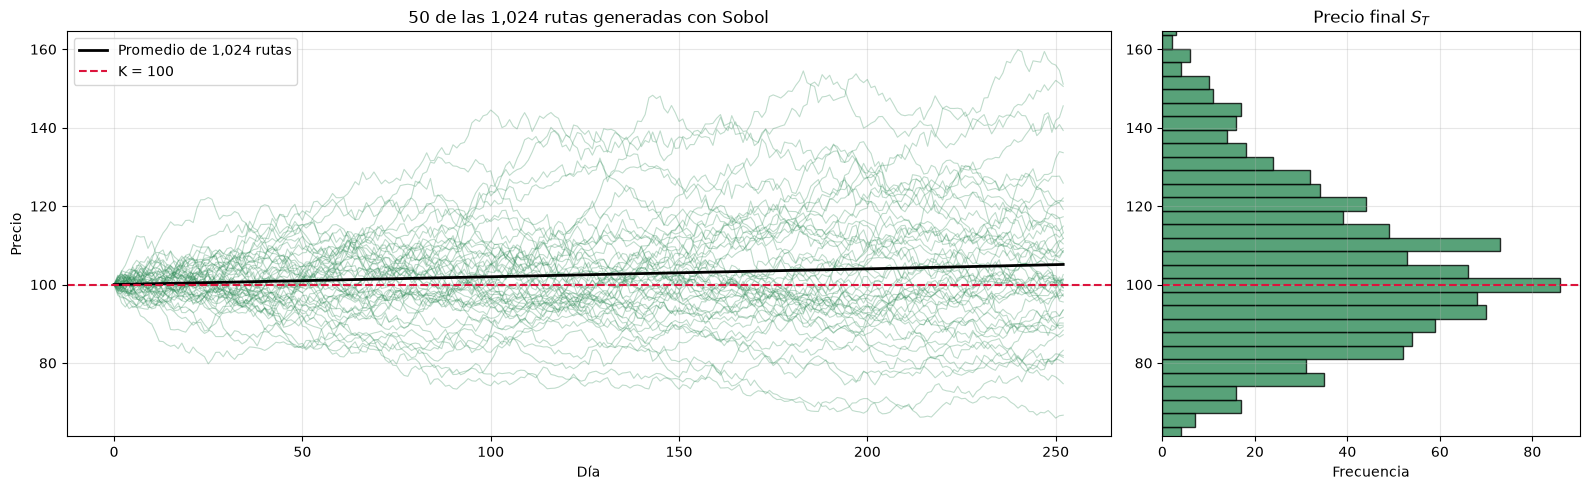

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5), gridspec_kw={"width_ratios": [2.5, 1]})

axes[0].plot(S_qmc[:50].T, color="seagreen", alpha=0.3, lw=0.8)
axes[0].plot(S_qmc.mean(axis=0), color="black", lw=2, label="Promedio de 1,024 rutas")
axes[0].axhline(K, color="crimson", ls="--", lw=1.5, label="K = 100")
axes[0].set_title("50 de las 1,024 rutas generadas con Sobol")
axes[0].set_xlabel("Día"); axes[0].set_ylabel("Precio")
axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].hist(S_qmc[:, -1], bins=40, orientation="horizontal", color="seagreen", edgecolor="black", alpha=0.8)
axes[1].axhline(K, color="crimson", ls="--", lw=1.5)
axes[1].set_ylim(axes[0].get_ylim())
axes[1].set_title("Precio final $S_T$")
axes[1].set_xlabel("Frecuencia"); axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Estabilidad de cada método: 30 repeticiones

Una sola corrida no dice cuál método es mejor. Se repite 30 veces cada uno, cambiando la semilla, y se mide cuánto varía el precio entre corridas. En QMC la semilla cambia el *scrambling* (una revoltura aleatoria de la secuencia), no la cobertura pareja de los puntos.

In [16]:
R = 30
res_qmc, res_mc = [], []

for k in range(R):
    Zq = norm.ppf(qmc.Sobol(d=n, scramble=True, seed=k).random(M))
    Sq = simular_rutas(Zq)
    res_qmc.append([desc*np.maximum(Sq[:, -1] - K, 0).mean(),
                    desc*np.maximum(Sq[:, 1:].mean(axis=1) - K, 0).mean()])

    Zm = np.random.default_rng(1000 + k).normal(0, 1, (M, n))
    Sm = simular_rutas(Zm)
    res_mc.append([desc*np.maximum(Sm[:, -1] - K, 0).mean(),
                   desc*np.maximum(Sm[:, 1:].mean(axis=1) - K, 0).mean()])

res_qmc = np.array(res_qmc)
res_mc  = np.array(res_mc)

pd.DataFrame({
    "Opción": ["Call europea", "Call asiática"],
    "Media MC": res_mc.mean(axis=0),
    "Desv. MC": res_mc.std(axis=0, ddof=1),
    "Media QMC": res_qmc.mean(axis=0),
    "Desv. QMC": res_qmc.std(axis=0, ddof=1),
    "Mejora (veces)": res_mc.std(axis=0, ddof=1) / res_qmc.std(axis=0, ddof=1)
}).round(4)

,Opción,Media MC,Desv. MC,Media QMC,Desv. QMC,Mejora (veces)
0,Call europea,10.4755,0.4022,10.4419,0.1279,3.1453
1,Call asiática,5.7613,0.2185,5.7782,0.0642,3.4025


### Gráfica de las 30 repeticiones

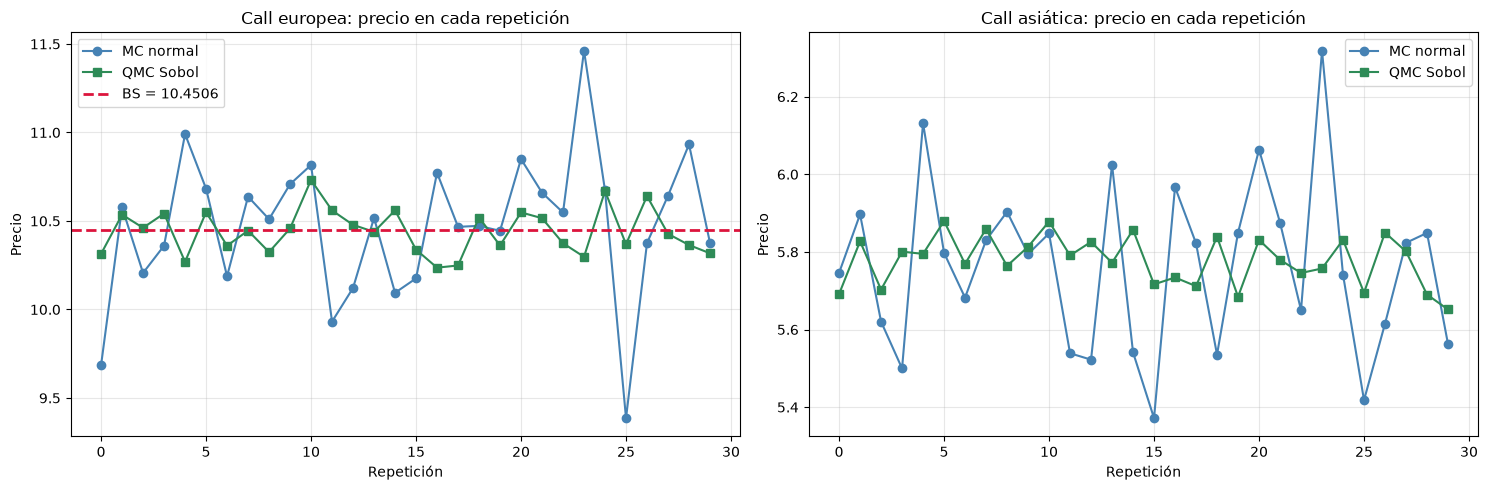

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for j, nombre in enumerate(["Call europea", "Call asiática"]):
    axes[j].plot(res_mc[:, j], "o-", color="steelblue", label="MC normal")
    axes[j].plot(res_qmc[:, j], "s-", color="seagreen", label="QMC Sobol")
    if j == 0:
        axes[j].axhline(bs, color="crimson", ls="--", lw=2, label=f"BS = {bs:.4f}")
    axes[j].set_title(f"{nombre}: precio en cada repetición")
    axes[j].set_xlabel("Repetición"); axes[j].set_ylabel("Precio")
    axes[j].legend(); axes[j].grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Efecto de la dimensión: europea con $d = 1$

La call europea solo depende de $S_T$, así que se puede simular de un salto con un solo número por escenario en vez de 252:

$$S_T = S_0 \exp\left[\left(r - \tfrac{\sigma^2}{2}\right)T + \sigma\sqrt{T}\,Z\right]$$

Se repite la comparación de 30 corridas con $d = 1$.

In [18]:
res_qmc_1d, res_mc_1d = [], []

for k in range(R):
    zq = norm.ppf(qmc.Sobol(d=1, scramble=True, seed=k).random(M)).ravel()
    zm = np.random.default_rng(1000 + k).normal(0, 1, M)

    ST_q = S0*np.exp((r - 0.5*sigma**2)*T + sigma*np.sqrt(T)*zq)
    ST_m = S0*np.exp((r - 0.5*sigma**2)*T + sigma*np.sqrt(T)*zm)

    res_qmc_1d.append(desc*np.maximum(ST_q - K, 0).mean())
    res_mc_1d.append(desc*np.maximum(ST_m - K, 0).mean())

res_qmc_1d = np.array(res_qmc_1d)
res_mc_1d  = np.array(res_mc_1d)

pd.DataFrame({
    "Simulación": ["Ruta completa (d = 252)", "Salto directo (d = 1)"],
    "Desv. MC": [res_mc[:, 0].std(ddof=1), res_mc_1d.std(ddof=1)],
    "Desv. QMC": [res_qmc[:, 0].std(ddof=1), res_qmc_1d.std(ddof=1)],
    "Mejora (veces)": [res_mc[:, 0].std(ddof=1) / res_qmc[:, 0].std(ddof=1),
                       res_mc_1d.std(ddof=1) / res_qmc_1d.std(ddof=1)],
    "Media QMC": [res_qmc[:, 0].mean(), res_qmc_1d.mean()]
}).round(4)

,Simulación,Desv. MC,Desv. QMC,Mejora (veces),Media QMC
0,Ruta completa (d = 252),0.4022,0.1279,3.1453,10.4419
1,Salto directo (d = 1),0.4002,0.0090,44.5079,10.4512


---
# Conclusiones

## Parte 1: cómo se reparten los puntos

**Los pseudoaleatorios cubren mal el espacio con pocos puntos.** Con 50 o 1,000 números uniformes el histograma está lejos de ser plano, y en dos dimensiones se forman amontonamientos y huecos. Solo con 100,000 números se empieza a ver una cobertura pareja.

**Sobol cubre parejo desde el principio.** Con 1,024 puntos cada barra del histograma tiene entre 63 y 65 valores cuando lo ideal es 64, y en dos dimensiones la discrepancia es unas 100 veces menor que la de los pseudoaleatorios (1.1e-05 contra 1.3e-03).

**Eso se traduce directamente en precisión.** Al estimar $\int_0^1 x^2\,dx = 1/3$:

| M | Error MC | Error QMC |
|---|---|---|
| 128 | 0.0079 | 0.0000000005 |
| 1,024 | 0.0108 | 0.0000000005 |
| 4,096 | 0.0069 | 0.0000000005 |

El error de Monte Carlo sigue la tasa $1/\sqrt{M}$ y además no baja de forma ordenada (con 512 puntos fue peor que con 128). Sobol es prácticamente exacto desde el inicio, porque en una dimensión y con una función suave la cobertura pareja es casi todo lo que se necesita.

## Parte 2: valuación de opciones

**Una corrida con 1,024 rutas:**

| Opción | MC normal | QMC Sobol | Black-Scholes |
|---|---|---|---|
| Call europea | 10.3522 | **10.4126** | 10.4506 |
| Call asiática | 5.5951 | **5.6995** | |

**30 repeticiones:**

| | Desv. MC | Desv. QMC | Mejora |
|---|---|---|---|
| Call europea, ruta completa ($d = 252$) | 0.402 | 0.128 | 3.1 veces |
| Call asiática ($d = 252$) | 0.218 | 0.064 | 3.4 veces |
| Call europea, salto directo ($d = 1$) | 0.400 | **0.009** | **44.5 veces** |

**QMC es más estable que Monte Carlo en todos los casos.** Con las mismas 1,024 rutas, el precio varía entre corridas unas 3 veces menos en las dos opciones. En la gráfica de las 30 repeticiones, MC llega a desviarse más de un peso del valor de Black-Scholes, mientras que QMC se mantiene en una banda angosta alrededor de él.

**La dimensión lo cambia todo.** La misma call europea mejora 3 veces con QMC si se simula día por día y **44 veces** si se simula de un salto. Con $d = 1$ el precio promedio de las 30 corridas fue 10.4512, a menos de un centavo de Black-Scholes. Es la maldición de la dimensionalidad: 1,024 puntos alcanzan para cubrir de forma pareja una línea, pero no un espacio de 252 dimensiones. Por eso en la Parte 1 Sobol era casi exacto y aquí la mejora es mucho más modesta.

**Por qué la mejora es menor con opciones que con la integral.** Además de la dimensión, el payoff tiene un codo en $K$: el $\max(\cdot, 0)$ no es una función suave, y QMC rinde más con funciones suaves.

## Lecciones prácticas

- **Usar la menor dimensión posible.** Si la opción solo depende de $S_T$, como la europea, se simula de un salto, no día por día.
- **Usar potencias de 2** para el número de rutas. Sobol pierde sus propiedades de balance con otros tamaños, y scipy lo advierte.
- **Usar scrambling** (`scramble=True`). Sin él los puntos son deterministas y no hay forma de medir la incertidumbre; con él se pueden hacer repeticiones como las de este notebook.
- **Para opciones que sí necesitan la ruta completa**, como la asiática, existe el *puente browniano*: reordena los números para que los primeros puntos de Sobol, los mejor distribuidos, definan los movimientos más importantes de la ruta. También se puede combinar QMC con variable de control, que en las asiáticas ya demostró ser muy efectiva.

**En resumen:** QMC no cambia el modelo, solo la forma de elegir los escenarios. Repartirlos de forma pareja reduce el error con el mismo número de rutas, y la ganancia es mayor entre menos dimensiones tenga el problema.